<a href="https://colab.research.google.com/github/HaticeCalik/P-center-plots/blob/main/ClosestAssignmentVisual.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

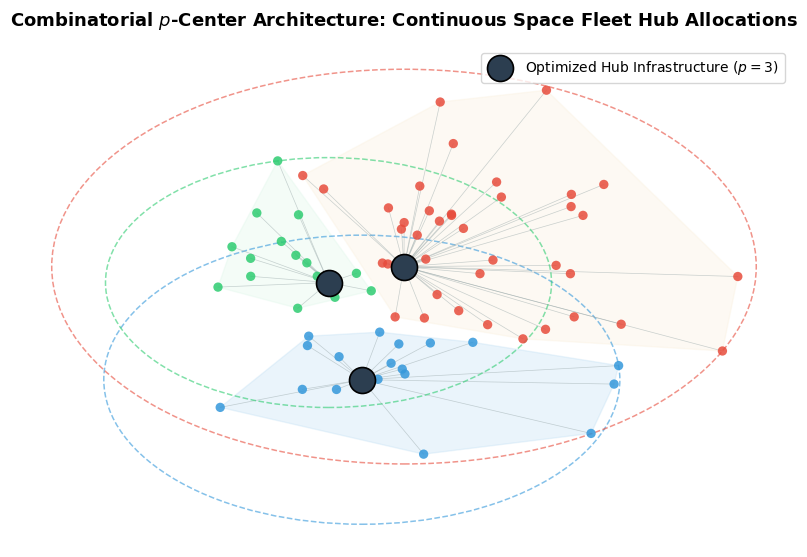

In [6]:
# generated by AI and modified by H. Calik. A random set of points are assigned to the closest center among a random set of centers.

import matplotlib.pyplot as plt
import numpy as np
from scipy.spatial import ConvexHull

fig, ax = plt.subplots(figsize=(10, 6.5))

# Generate large-scale continuous space facility logistics datasets (75 demand sites)
np.random.seed(88)
X = np.random.randn(75, 2) * 2.5

# Rigorous evaluation points selecting p=3 centers satisfying absolute minimax radius criteria
centers_idx = [12, 42, 64]
centers = X[centers_idx]

# Map every individual demand node to its closest optimized covering hub vertex (Voronoi allocation partitioning)
allocations = {0: [], 1: [], 2: []}
for i, pt in enumerate(X):
    dists = [np.linalg.norm(pt - c) for c in centers]
    closest_hub = np.argmin(dists)
    allocations[closest_hub].append(pt)

colors_p = ['#3498db', '#e74c3c', '#2ecc71']
fill_p = ['#aed6f1', '#f9ebd2', '#d5f5e3']

# Draw minimax allocation geometries, vectors, and maximal coverage boundary vectors
for c_idx, c_pos in enumerate(centers):
    pts = np.array(allocations[c_idx])

    # Calculate absolute maximum covering threshold distance for the p-center objective function
    radii = [np.linalg.norm(p - c_pos) for p in pts]
    max_r = np.max(radii)

    # Trace the exact minimax bounding circle footprint
    circle = plt.Circle((c_pos[0], c_pos[1]), max_r, color=colors_p[c_idx], fill=False, linestyle='--', linewidth=1.1, alpha=0.6)
    ax.add_patch(circle)

    # Draw subtle fill for the convex boundaries of the cluster allocation group
    if len(pts) > 2:
        hull = ConvexHull(pts)
        ax.fill(pts[hull.vertices,0], pts[hull.vertices,1], color=fill_p[c_idx], alpha=0.25, zorder=0)

    # Plot thin allocations lines linking source points to destination hubs
    for pt in pts:
        ax.plot([c_pos[0], pt[0]], [c_pos[1], pt[1]], color='#95a5a6', linewidth=0.5, alpha=0.5, zorder=1)

    # Draw individual demand coordinates
    ax.scatter(pts[:,0], pts[:,1], color=colors_p[c_idx], s=45, alpha=0.85, edgecolors='none', zorder=2)

# Draw primary facility star structures representing optimized hubs
ax.scatter(centers[:,0], centers[:,1], color='#2c3e50', marker='o', s=350, edgecolors='black', linewidths=1.2, zorder=4, label='Optimized Hub Infrastructure ($p=3$)')

ax.set_title("Combinatorial $p$-Center Architecture: Continuous Space Fleet Hub Allocations", fontsize=13, fontweight='bold', pad=15)
ax.legend(loc='upper right', frameon=True)
ax.axis('off')
plt.show()
